<small>
Introducción a la Ciencia de Datos | Posgrado en Ciencias de la Computación — CICESE
Tarea 5: CNN compacta con Global Average Pooling
</small>

---

# Tarea 5: CNN compacta con Global Average Pooling (MNIST)

El objetivo es diseñar una red convolucional con *Global Average Pooling* (GAP) que supere el **95 % de exactitud en validación** en MNIST usando **menos de 54 330 parámetros entrenables**, que es el total de la CNN base con Flatten. Entre las arquitecturas que cumplan ambos requisitos se elige la de menos parámetros, y después se mide qué tan bien reconoce los dígitos cuando cambia su posición.

## 1. Datos y funciones del notebook de clase

#### 1. Importaciones

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3" 
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from IPython.display import display
from sklearn.model_selection import train_test_split
keras = tf.keras

- `TF_CPP_MIN_LOG_LEVEL = "3"`: silencia los mensajes internos de Tensorflow.
- `keras`: API de tensorflow para construir y entrenar redes.

---

#### 2. Constantes de configuracion

In [2]:
SEMILLA = 42
N_ENT, N_VAL, N_PRUEBA = 8000, 1500, 2000
MARGEN = 4
CAPAS = (16, 16)
LOTE = 128
EPOCAS = 20
TASA = 0.001

- `N_ENT`, `N_VAL`, `N_PRUEBA`: cuantas imagenes hay en cada particion: Se usa un subconjunto de MNIST para que entrenar sea rapido en CPU.
- `MARGEN`: pixeles negros que se agregan por lado.
- `CAPAS`: filtros de la CNN base (dos convoluciones de 16).
- `LOTE`, `EPOCAS`, `TASA`: tamaño de lote, numero de pasadas por los datos y tasa de aprendizaje de Adam.

---

#### 3. Carga de MNIST y particiones

In [3]:
(x_des, y_des), (x_test, y_test) = keras.datasets.mnist.load_data()

Descarga de MNIST (solo por primera vez) y lo separa en:
- Desarrollo: 60 000 imagenes del conjunto oficial de entrenamiento (`x_des`, `y_des`)
- Prueba: 10 000 imagenes (`x_test`, `y_test`)

In [4]:
i_ent, i_val = train_test_split(
    np.arange(len(y_des)), train_size=N_ENT, test_size=N_VAL,
    stratify=y_des, random_state=SEMILLA,
)

- No divide las imagenes directamente: divide sus indices `(np.arange(60000))`
- Toma 8 000 indices para entrenamiento y 1 500 para validacion. El resto de las 60 000 se descarta.
- `stratify=y_des` mantiene en cada particion la misma proporcion de cada digito que hay en el total.

In [5]:
i_prueba, _ = train_test_split(
    np.arange(len(y_test)), train_size=N_PRUEBA, stratify=y_test,
    random_state=SEMILLA,
)

- Aqui hacemos lo mismo que con la parte de arriba: tomamos 2 000 indices estratificados, y `_` descarta el resto. La validacion sale del conjunto de entrenamiento y la prueba del conjunto oficial del prueba, asi que nunca se mezclan.

---

#### 4. Preparar las imagenes

In [6]:
def preparar_imagenes(imagenes):
    imagenes = np.pad(imagenes, ((0,0), (MARGEN, MARGEN), (MARGEN, MARGEN)))
    return imagenes[..., None].astype(np.float32) / 255.0

1. `np.pad` agrega ceros (negro) al rededor de cada imagen.
2. `[...,None]` agrega el eje del canal: `(n, 36, 36)` -> (n, 36, 36, 1)
3. `astype(np.float32) / 255.0` pasa los pixeles de enteros 0-255 a decimales 0-1, que es una mejor escala para entrenar.

In [7]:
X_ent, y_ent = preparar_imagenes(x_des[i_ent]), y_des[i_ent]
X_val, y_val = preparar_imagenes(x_des[i_val]), y_des[i_val]
X_prueba, y_prueba = preparar_imagenes(x_test[i_prueba]), y_test[i_prueba]
FORMA = X_ent.shape[1:]

Con los indices se seleccionan las imagenes y etiquetas de cada particion, y se preparan. `FORMA` quedan en `(36, 36, 1)`: es la forma de entrada que reciben todas las redes.

In [8]:
for nombre, X in [("Entrenamiento", X_ent), ("Validacion", X_val), ("Prueba", X_prueba)]:
    print(f"{nombre}: {X.shape}")

Entrenamiento: (8000, 36, 36, 1)
Validacion: (1500, 36, 36, 1)
Prueba: (2000, 36, 36, 1)


Imprime las formas para verificar, por ejemplo `Entrenamiento: (8000, 36, 36, 1)`

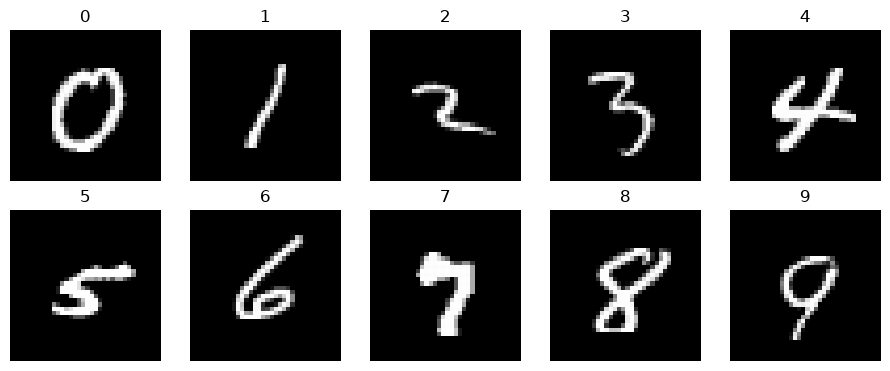

In [9]:
fig, ejes = plt.subplots(2, 5, figsize=(9, 3.6), layout="constrained")
for digito, ax in enumerate(ejes.flat):
    i = np.flatnonzero(y_ent == digito)[0]
    ax.imshow(X_ent[i, ..., 0], cmap="gray", vmin=0, vmax=1)
    ax.set_title(str(digito))
    ax.axis("off")
plt.show()

---

#### 5. Crear CNN (modelos base)

In [10]:
def crear_cnn(filtros=CAPAS, padding="same", pooling="max", stride=1, cabeza="flatten"):
    capas = [keras.Input(shape=FORMA)]
    for i, n_filtros in enumerate(filtros):
        capas.append(keras.layers.Conv2D(
            n_filtros, 3, strides=stride if i == 0 else 1,
            padding=padding, activation="relu", name=f"conv_{i + 1}", # type: ignore
        ))
    if pooling == "max":
        capas.append(keras.layers.MaxPooling2D(2, name="pool"))
    elif pooling == "average":
        capas.append(keras.layers.AveragePooling2D(2, name="pool"))
    elif pooling != "sin":
        raise ValueError("pooling debe ser 'max', 'average' o 'sin'")

    if cabeza == "flatten":
        capas.append(keras.layers.Flatten(name="vector"))
    elif cabeza == "gap":
        capas.append(keras.layers.GlobalAveragePooling2D(name="vector"))
    else:
        raise ValueError("cabeza debe ser 'flatten' o 'gap'")

    capas.append(keras.layers.Dense(10, activation="softmax", name="salida"))
    return keras.Sequential(capas, name=f"cnn_{cabeza}")

1. Se introducen los parametros de entrada para la CNN:
- `filtros`: cuantas convoluciones y cuantos filtros tiene cada una
- `padding`: si se rellenan los bordes para conservar el tamaño
- `pooling`: Tipo de pooling final: `"max"`, `"average"` o `"sin"`.
- `stride`: El paso de la primera convolucion.
- `cabeza`: Como se convierte el mapa en vector: `flatten` o `gap`

2. Entrada, con `capas = [keras.Input(shape=FORMA)]` empezamos una lista con la capa de entrada, que recibe imagenes de 36x36x1 (36 de alto, 36 de ancho, 1 canal de gris). El resto de la funcion solo va agregando capas a esta lista.

3. Las convoluciones, se recorre la tupla `filtros` y agrega una convolucion por cada numero. Con (16, 16), enumerate da `i = 0, n_filtros=16` y luego `i = 1, n_filtros=16` asi que se crean dos capas. Cada `Conv2D`recibe:

- `n_filtros`: cuantos filtros (detectores) aprende la capa. Cada filtro produce un mapa de salida, o canal.
- `3`: el kernel es de 3x3, es decir, cada filtro mira ventanas de 3x3 pixeles.
- `strides=stride if i == 0 else 1`: solo la primera capa (i == 0) usa el stride que seleccionamos cuando creamos la CNN. Si cambiaramos stride=2 la imagen avanzaria de 2 en 2 y se reduciria a la mitad.
- `padding="same"`: rellena el borde con ceros para que la salida tenga el mismo tamaño (36 -> 36). 
- `activacion="relu"`: convierte los negativos en 0 y deja los positivos igual.
- `name=f"conv_{i+1}`: nombra las capas `conv_1`, `conv_2`, etc.

4. El pooling, agrega un solo pooling de 2x2 despues de todas las convoluciones. Divide cada ventana de 2x2 en un solo valor, asi que el mapa pasa de 36x36 a 18x18.

5. Salida y modelo, 

```Python
capas.append(keras.layers.Dense(10, activation="softmax", name="salida"))
return keras.Sequential(capas, name=f"cnn_{cabeza}")
```
- `Dense(10, softmax)` tiene 10 neuronas, una por digito. Softmax convierte sus salidas en probabilidades que suman 1.
- `keras.Sequential(capas)` encadena la lista en orden: la salida de cada capa es la entrada de la siguiente: El modelo se llama cnn_flatten o cnn_gap.

In [11]:
def lotes(X, y=None, mezclar=False):
    datos = tf.data.Dataset.from_tensor_slices(X if y is None else (X, y))
    if mezclar:
        datos = datos.shuffle(len(X), seed=SEMILLA)
    opciones = tf.data.Options()
    opciones.threading.private_threadpool_size = 2
    return datos.batch(LOTE).with_options(opciones).prefetch(1)

In [12]:
def entrenar(constructor, **configuracion):
    keras.utils.set_random_seed(SEMILLA)
    modelo = constructor(**configuracion)
    modelo.compile(
        optimizer=keras.optimizers.Adam(learning_rate=TASA),
        loss="sparse_categorical_crossentropy",
        metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")],
    )
    historial = modelo.fit(
        lotes(X_ent, y_ent, mezclar=True),
        validation_data=lotes(X_val, y_val),
        epochs=EPOCAS, verbose=0, shuffle=False,  # lotes() ya mezcla los datos
    ).history
    return modelo, historial

modelo_flatten, hist_flatten = entrenar(crear_cnn, cabeza="flatten")
modelo_gap_base, hist_gap_base = entrenar(crear_cnn, cabeza="gap")
modelo_flatten.summary()
modelo_gap_base.summary()

Model: "cnn_flatten"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv_1 (Conv2D)                 │ (None, 36, 36, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2 (Conv2D)                 │ (None, 36, 36, 16)     │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool (MaxPooling2D)             │ (None, 18, 18, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vector (Flatten)                │ (None, 5184)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida (Dense)                  │ (None, 10)             │        51,850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 162,992 (636.69 KB)

 Trainable params: 54,330 (212.23 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 108,662 (424.46 KB)

... (2 outputs left out)

 Total params: 7,952 (31.07 KB)

 Trainable params: 2,650 (10.35 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 5,302 (20.71 KB)

---

#### 6. Funciones auxiliares

In [13]:
def parametros(modelo):
    return sum(int(np.prod(v.shape)) for v in modelo.trainable_weights)

`parametros`: 
- Recorre los pesos entrenables del modelo (kernels y sesgos). Para cada uno multiplica sus dimensiones con `np.prod`; por ejemplo un kernel (3, 3, 1, 16) = 144 numeros. Al final suma todo.

In [14]:
def desplazar(imagenes, dy, dx):
    if max(abs(dy), abs(dx)) > MARGEN:
        raise ValueError("Usar un desplazamiento dentro del margen de la imagen")
    alto, ancho = imagenes.shape[1:3]
    resultado = np.zeros_like(imagenes)
    origen_y = slice(max(-dy, 0), alto - max(dy, 0))
    origen_x = slice(max(-dx, 0), ancho - max(dx, 0))
    destino_y = slice(max(dy, 0), alto - max(-dy, 0))
    destino_x = slice(max(dx, 0), ancho - max(-dx, 0))
    resultado[:, destino_y, destino_x, :] = imagenes[:, origen_y, origen_x, :]
    return resultado

`desplazar`:
- Revisa que el desplazamiento no pase de 4px, el margen;
- Crea un lienzo negro del mismo tamaño (np.zeros_like);
- Calcula que parte de la imagen se copia (origen) y donde se pega (`destino`);
- Copia la imagen corrida  `dy` pixeles en vertical y `dx` en horizontal.

In [15]:
def predecir(modelo, imagenes):
    return modelo.predict(lotes(imagenes), verbose=0).argmax(axis=1)

`predecir`:
- Pasa las imagenes en lotes por el modelo;
- `predict` da 10 probabilidades por imagen;
- `argmax(axis=1)` se queda con el digito mas probable

---

#### 2. Modelos de referencia

In [16]:
PARAMS_FLATTEN = parametros(modelo_flatten)

tabla_ref = pd.DataFrame([
    {"Modelo": "CNN + Flatten",
     "Parámetros entrenables": PARAMS_FLATTEN,
     "Exactitud validación (%)": 100 * hist_flatten["val_accuracy"][-1]},
    {"Modelo": "CNN + GAP (base)",
     "Parámetros entrenables": parametros(modelo_gap_base),
     "Exactitud validación (%)": 100 * hist_gap_base["val_accuracy"][-1]},
])
display(tabla_ref.round(2))

,Modelo,Parámetros entrenables,Exactitud validación (%)
0,CNN + Flatten,54330,96.8
1,CNN + GAP (base),2650,44.0


1. Se guardan los parametros de Flatten en `PARAMS_FLATTEN`, que da 54 330. Se usa despues como el limite que no hay que pasar.
2. `hist_flatten["val_accuracy"]` es la lista de exactitud de validacion de las 20 epocas. `[-1]` toma la ultima, que es la que pide la tarea. Se multiplica por 100 para expresarla en %
3. Arma una tabla de pandas con una fila por modelo y la muestra redondeada a 2 decimales.

---

#### 3. Variantes con GAP

##### 3.1 Descripción de las variantes

Todas las variantes terminan en `GlobalAveragePooling2D` seguido de una capa densa de 10 clases. Cada arquitectura se describe como una secuencia de bloques:

- **Un número** es una convolución con ese número de filtros (ReLU, `padding="same"`, stride 1, kernel 3 × 3 salvo que se indique `k5`).
- **`P`** es un *max pooling* de 2 × 2, que reduce la resolución así: 36 → 18 → 9 → 4.

Por ejemplo, `8-P-16-P-32` es conv(8) → pool → conv(16) → pool → conv(32) → GAP → Dense(10).

Las variantes se organizan por la decisión que cambian. Las comparaciones de **una sola decisión** permiten interpretar su efecto:

| Comparación | Variante A | Variante B | Qué cambia |
|:--|:--|:--|:--|
| Profundidad | `16-16-P` (GAP base) | `16-16-16-P` | Se agrega una convolución |
| **Ubicación del pooling** | `16-16-16-P` | `16-P-16-P-16` | Mismas capas y mismos parámetros; el pooling se intercala |
| **Ubicación del pooling** | `8-16-32-P` | `8-P-16-P-32` | Mismas capas y mismos parámetros; el pooling se intercala |
| Tamaño del kernel | `8-P-16-P-32` | `8-P-16-P-32 (k5)` | Kernel 3 × 3 → 5 × 5 |
| Pooling final | `8-8-P-16-16-P-32-32` | `8-8-P-16-16-P-32-32-P` | Se agrega un pooling antes de GAP |
| Ancho | `8-8-P-16-16-P-32-32-P` | `6-6-P-12-12-P-24-24-P` y otras | Se reducen los filtros de todas las capas |


##### 3.2 Crear GAP

In [17]:
def crear_gap(bloques, kernel=3):
    capas = [keras.Input(shape=FORMA)]
    for b in bloques:
        if b == "P":
            capas.append(keras.layers.MaxPooling2D(2))
        else:
            capas.append(keras.layers.Conv2D(b, kernel, padding="same", activation="relu"))
    capas.append(keras.layers.GlobalAveragePooling2D(name="vector"))
    capas.append(keras.layers.Dense(10, activation="softmax", name="salida"))
    return keras.Sequential(capas)

`crear_gap`:
- Es como `crear_cnn`, pero recibe una lista `bloques` que dice qué capa va en cada posición.
- Si el elemento es `"P"`, agrega un *max pooling* de 2 × 2, que reduce el mapa a la mitad.
- Si es un número, agrega una convolución con ese número de filtros (kernel 3 × 3 por defecto, `padding="same"`, ReLU).
- Al final siempre agrega **GAP** y la capa de salida de 10 clases.
- La diferencia clave con `crear_cnn` es que **el pooling puede ir entre las convoluciones**, no solo al final.

In [18]:
def nombre_variante(bloques, kernel=3):
    nombre = "-".join(str(b) for b in bloques)
    return nombre if kernel == 3 else f"{nombre} (k{kernel})"

`nombre_variante`:
- Convierte la lista de bloques en texto para las tablas, por ejemplo `[6, 6, "P", 12]` → `"6-6-P-12"`. Si el kernel no es 3, le agrega `(k5)`.

##### 3.3 Lista de variantes

In [19]:
variantes = [
    ("GAP base",            dict(bloques=[16, 16, "P"])),
    ("Profundidad",         dict(bloques=[16, 16, 16, "P"])),
    ("Ubicación pooling",   dict(bloques=[16, "P", 16, "P", 16])),
    ("Ubicación pooling",   dict(bloques=[8, 16, 32, "P"])),
    ("Ubicación pooling",   dict(bloques=[8, "P", 16, "P", 32])),
    ("Tamaño de kernel",    dict(bloques=[8, "P", 16, "P", 32], kernel=5)),
    ("Tercera reducción",   dict(bloques=[8, "P", 16, "P", 32, "P", 64])),
    ("Pooling final",       dict(bloques=[8, 8, "P", 16, 16, "P", 32, 32])),
    ("Pooling final",       dict(bloques=[8, 8, "P", 16, 16, "P", 32, 32, "P"])),
    ("Ancho",               dict(bloques=[8, 8, "P", 12, 12, "P", 24, 24, "P"])),
    ("Ancho",               dict(bloques=[6, 6, "P", 12, 12, "P", 24, 24, "P"])),
    ("Ancho",               dict(bloques=[8, 8, "P", 16, 16, "P", 16, 16, "P"])),
    ("Ancho",               dict(bloques=[6, 6, "P", 12, 12, "P", 20, 20, "P"])),
    ("Ancho",               dict(bloques=[4, 4, "P", 8, 8, "P", 24, 24, "P"])),
]


- Es una lista de 14 pares `(grupo, configuración)`; todavía no entrena nada.
- El **grupo** indica qué decisión se está probando.
- La **configuración** es un diccionario con los argumentos para `crear_gap`.
- Se cumplen los requisitos de la tarea: más de 6 variantes y varias comparaciones de una sola decisión (los pares de "Ubicación pooling" tienen las mismas capas y solo mueven el pooling; "Tamaño de kernel" y "Pooling final" cambian una sola cosa).

##### 3.4 Entrenamiento de las variantes

Cada variante se entrena con la función `entrenar`, con la misma semilla, datos y 20 épocas que los modelos base. Se registra la exactitud de validación al final de las 20 épocas y el número de parámetros entrenables del modelo completo.

In [20]:
modelos_gap, historiales_gap, filas = {}, {}, []

for grupo, cfg in variantes:
    nombre = nombre_variante(**cfg)
    print(f"Entrenando {nombre}")
    modelo, historial = entrenar(crear_gap, **cfg)
    modelos_gap[nombre], historiales_gap[nombre] = modelo, historial
    forma = modelo.get_layer("vector").input.shape[1:]
    filas.append({
        "Comparacion": grupo,
        "Arquitectura": nombre,
        "Convoluciones": sum(b != "P" for b in cfg["bloques"]),
        "Mapas antes de GAP": " x ".join(str(d) for d in forma),
        "Parametros entrenables": parametros(modelo),
        "Exactitud validacion (%)": 100 * historial["val_accuracy"][-1],
    })

tabla_val = pd.DataFrame(filas)
tabla_val["Cumple"] = ((tabla_val["Exactitud validacion (%)"] > 95)
                       & (tabla_val["Parametros entrenables"] < PARAMS_FLATTEN))
display(tabla_val.round(2))

Entrenando 16-16-P


Entrenando 16-16-16-P


Entrenando 16-P-16-P-16


Entrenando 8-16-32-P


Entrenando 8-P-16-P-32


Entrenando 8-P-16-P-32 (k5)


... (5 outputs left out)

Entrenando 8-8-P-16-16-P-16-16-P


Entrenando 6-6-P-12-12-P-20-20-P


Entrenando 4-4-P-8-8-P-24-24-P


,Comparacion,Arquitectura,Convoluciones,Mapas antes de GAP,Parametros entrenables,Exactitud validacion (%),Cumple
0,GAP base,16-16-P,2,18 x 18 x 16,2650,44.00,False
1,Profundidad,16-16-16-P,3,18 x 18 x 16,4970,53.33,False
2,Ubicación pooling,16-P-16-P-16,3,9 x 9 x 16,4970,86.53,False
3,Ubicación pooling,8-16-32-P,3,18 x 18 x 32,6218,54.13,False
4,Ubicación pooling,8-P-16-P-32,3,9 x 9 x 32,6218,89.67,False
5,Tamaño de kernel,8-P-16-P-32 (k5),3,9 x 9 x 32,16586,93.73,False
6,Tercera reducción,8-P-16-P-32-P-64,4,4 x 4 x 64,25034,95.67,True
7,Pooling final,8-8-P-16-16-P-32-32,6,9 x 9 x 32,18370,94.93,False
8,Pooling final,8-8-P-16-16-P-32-32-P,6,4 x 4 x 32,18370,96.40,True
9,Ancho,8-8-P-12-12-P-24-24-P,6,4 x 4 x 24,10922,96.53,True


- Por cada variante se genera su nombre, se entrena con `entrenar` y se guarda el modelo en `modelos_gap` para poder usar el ganador después sin reentrenar.
- `modelo.get_layer("vector").input.shape` lee la forma del mapa que llega a GAP (por ejemplo `4 × 4 × 24`).
- Cada fila guarda el grupo, el nombre, cuántas convoluciones tiene, la forma antes de GAP, los parámetros y la exactitud de validación final.
- La columna **`Cumple`** es `True` solo si la exactitud es **mayor** a 95 % y los parámetros son menos de 54 330.

##### 3.5 Interpretación

**Ubicación del pooling (la decisión más importante)**

| Variante A | Exactitud | Variante B | Exactitud | Parámetros (ambas) |
|:--|:--:|:--|:--:|:--:|
| `16-16-16-P` | 53.33 % | `16-P-16-P-16` | **86.53 %** | 4 970 |
| `8-16-32-P` | 54.13 % | `8-P-16-P-32` | **89.67 %** | 6 218 |

- **Mismo número de parámetros, +33 a +36 puntos:** el pooling no tiene pesos, así que moverlo de lugar no cambia el tamaño del modelo, pero sí cuánto de la imagen ve cada neurona.
- **Campo receptivo:** con tres convoluciones 3 × 3 sin pooling intermedio, cada neurona final ve un parche de **7 × 7** píxeles. Al intercalar el pooling, ese parche crece a **18 × 18**. Como GAP promedia cada canal sobre toda la imagen, cada canal debe indicar por sí solo qué dígito hay, y para eso necesita ver la forma completa y no solo un trazo.

**Otras decisiones**

- **Profundidad sin pooling intermedio:** agregar una convolución al GAP base apenas sube de 44.00 % a 53.33 %.
- **Kernel 5 × 5:** sube de 89.67 % a 93.73 %, pero casi triplica los parámetros (6 218 → 16 586). Es menos eficiente que agregar profundidad con pooling.
- **Pooling final:** en `8-8-P-16-16-P-32-32`, agregar un tercer pooling antes de GAP sube de 94.93 % a **96.40 %** con los mismos 18 370 parámetros. Un tercer nivel de reducción amplía el campo receptivo hasta cubrir los 36 píxeles de la entrada.
- **Ancho:** una vez fijada la estructura de tres bloques con dos convoluciones cada uno, se pueden reducir los filtros. Con 6-12-24 filtros se mantiene en 96.40 %, pero al reducir más ya no cumple el requisito de **superar** el 95 %: `6-6-P-12-12-P-20-20-P` llega justo a 95.00 % y `4-4-P-8-8-P-24-24-P` baja a 94.87 %.

##### 3.6 Selección de la arquitectura


In [21]:
candidatas = tabla_val[tabla_val["Cumple"]].sort_values("Parametros entrenables")
seleccion = candidatas.iloc[0]
NOMBRE_SEL = seleccion["Arquitectura"]
modelo_sel = modelos_gap[NOMBRE_SEL]
params_sel = int(seleccion["Parametros entrenables"])
ahorro = PARAMS_FLATTEN -params_sel

print(f"Seleccionada: {NOMBRE_SEL}")
print(f"Exactitud de validacion: {seleccion["Exactitud validacion (%)"]:.2f} %")
print(f"Parametros: {params_sel:,} frente a {PARAMS_FLATTEN:,} de Flatten")
print(f"Ahorro: {ahorro:,} parametros ({100 * ahorro / PARAMS_FLATTEN:.1f} % menos)")
modelo_sel.summary()

Seleccionada: 6-6-P-12-12-P-24-24-P
Exactitud de validacion: 96.40 %
Parametros: 10,432 frente a 54,330 de Flatten
Ahorro: 43,898 parametros (80.8 % menos)


Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_39 (Conv2D)              │ (None, 36, 36, 6)      │            60 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_40 (Conv2D)              │ (None, 36, 36, 6)      │           330 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_20 (MaxPooling2D) │ (None, 18, 18, 6)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_41 (Conv2D)              │ (None, 18, 18, 12)     │           660 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_42 (Conv2D)              │ (None, 18, 18, 12)     │         1,308 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_21 (MaxPooling2D) │ (None, 9, 9, 12)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_43 (Conv2D)              │ (None, 9, 9, 24)       │         2,616 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_44 (Conv2D)              │ (None, 9, 9, 24)       │         5,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_22 (MaxPooling2D) │ (None, 4, 4, 24)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vector (GlobalAveragePooling2D) │ (None, 24)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida (Dense)                  │ (None, 10)             │           250 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,298 (122.26 KB)

 Trainable params: 10,432 (40.75 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 20,866 (81.51 KB)

- Se filtran las variantes que cumplen y se ordenan de menos a más parámetros.
- `.iloc[0]` toma la primera, es decir, la de menos parámetros.
- Se recupera ese modelo ya entrenado de `modelos_gap`, sin volver a entrenarlo.
- Se calcula el ahorro: 54 330 menos los parámetros del modelo seleccionado, también en porcentaje.


##### 3.7 Curvas de validación por época

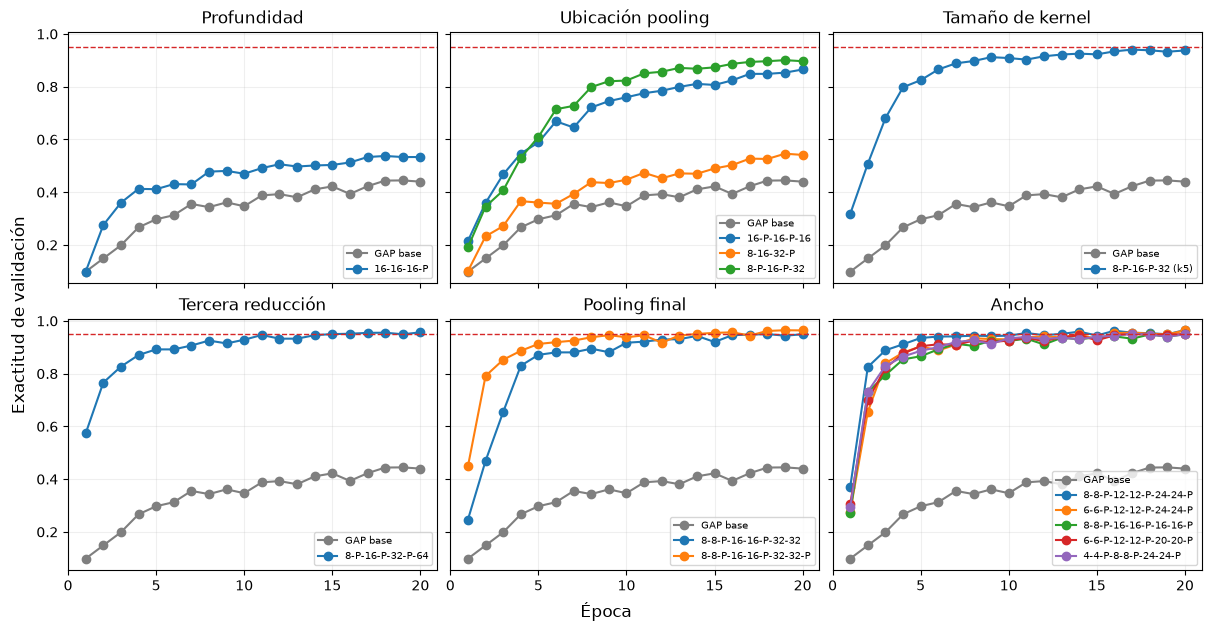

In [22]:
def curvas(ax, historial, metrica, etiqueta, color, estilo="-"):
    valores = historial[metrica]
    ax.plot(range(1, len(valores) + 1), valores, estilo, marker="o",
            label=etiqueta, color=color)

grupos = [g for g in tabla_val["Comparacion"].unique() if g != "GAP base"]
nombre_base = tabla_val.loc[tabla_val["Comparacion"] == "GAP base", "Arquitectura"].iloc[0]
n_col = 3
n_fil = -(-len(grupos) // n_col)  # división hacia arriba

fig, ejes = plt.subplots(n_fil, n_col, figsize=(12, 3.1 * n_fil),
                         sharex=True, sharey=True, layout="constrained")
for ax, grupo in zip(ejes.flat, grupos):
    curvas(ax, historiales_gap[nombre_base], "val_accuracy", "GAP base", "C7")
    nombres = tabla_val.loc[tabla_val["Comparacion"] == grupo, "Arquitectura"]
    for k, nombre in enumerate(nombres):
        curvas(ax, historiales_gap[nombre], "val_accuracy", nombre, f"C{k}")
    ax.axhline(0.95, color="C3", ls="--", lw=1)
    ax.set(title=grupo, xticks=range(0, EPOCAS + 1, 5))
    ax.legend(fontsize=7, loc="lower right")
    ax.grid(alpha=0.2)

for ax in list(ejes.flat)[len(grupos):]:
    ax.axis("off")
fig.supxlabel("Época")
fig.supylabel("Exactitud de validación")
plt.show()

- `curvas`: dibuja una métrica del historial época por época.
- Se hace un panel por cada grupo de comparación. En gris aparece el GAP base como referencia y en color las variantes del grupo. La línea roja marca el 95 %.
- **Ubicación del pooling:** las variantes con pooling intercalado (`16-P-16-P-16`, `8-P-16-P-32`) suben mucho más rápido y terminan más de 30 puntos arriba que sus equivalentes con pooling solo al final, con los mismos parámetros.
- **Pooling final y Ancho:** las variantes de tres bloques cruzan el 95 % alrededor de la época 12–15 y después se estabilizan, por lo que el presupuesto de 20 épocas es suficiente para compararlas.

##### 3.8 Interpretación de la selección

| Variante que cumple | Parámetros | Exactitud de validación |
|:--|:--:|:--:|
| **`6-6-P-12-12-P-24-24-P`** | **10 432** | **96.40 %** |
| `8-8-P-12-12-P-24-24-P` | 10 922 | 96.53 % |
| `8-8-P-16-16-P-32-32-P` | 18 370 | 96.40 % |
| `8-P-16-P-32-P-64` | 25 034 | 95.67 % |

- **Arquitectura seleccionada:** `6-6-P-12-12-P-24-24-P`, con seis convoluciones agrupadas en tres bloques de dos, cada bloque seguido de un *max pooling*. Los mapas llegan a GAP con forma 4 × 4 × 24.
- **Ahorro frente a Flatten:** 54 330 − 10 432 = **43 898 parámetros (80.8 % menos)**. La capa de salida pasa de 51 850 pesos a solo 250.
- **Variantes en el límite:** `8-8-P-16-16-P-16-16-P` (8 962) y `6-6-P-12-12-P-20-20-P` (8 368) obtuvieron exactamente 95.00 %. No se seleccionan porque la tarea pide **superar** el 95 %.

---

#### 4. Efecto del desplazamiento

Se comparan los tres modelos sobre las mismas 2 000 imágenes de prueba, **sin reentrenar**, usando la función `desplazar`:

- **0 píxeles:** una sola evaluación con las imágenes originales.
- **2 y 4 píxeles:** se promedia la exactitud de los desplazamientos hacia arriba, abajo, izquierda y derecha.

La caída se reporta en puntos porcentuales como $\text{Acc}(0\,\text{px}) - \text{Acc}(4\,\text{px})$.

##### 4.1 Exactitud sin desplazar (0 px)

In [23]:
modelos = {
    "CNN + Flatten": modelo_flatten,
    "CNN + GAP base": modelo_gap_base,
    f"GAP seleccionado: ({NOMBRE_SEL})": modelo_sel,
}

distancias = (0, 2, 4)

exactitudes = {nombre: [100 * np.mean(predecir(m, X_prueba) == y_prueba)]
               for nombre, m in modelos.items()}
exactitudes

{'CNN + Flatten': [np.float64(97.1)],
 'CNN + GAP base': [np.float64(46.400000000000006)],
 'GAP seleccionado: (6-6-P-12-12-P-24-24-P)': [np.float64(96.55)]}

- Se juntan los tres modelos que pide la tarea en un diccionario para recorrerlos con un ciclo.
- Para cada modelo se predicen las 2 000 imágenes de prueba originales. `predicción == y_prueba` da `True`/`False` por imagen y `np.mean` obtiene la proporción de aciertos.
- Aquí se usa el conjunto de prueba por primera vez; la selección ya se hizo solo con validación.

##### 4.2 Exactitud desplazando 2 y 4 px

In [24]:
for distancia in distancias[1:]:
    por_direccion = {nombre: [] for nombre in modelos}
    for dy, dx in ((0, distancia), (0, -distancia), (distancia, 0), (-distancia, 0)):
        imagenes = desplazar(X_prueba, dy, dx)
        for nombre, m in modelos.items():
            por_direccion[nombre].append(100 * np.mean(predecir(m, imagenes) == y_prueba))
    for nombre, valores in por_direccion.items():
        exactitudes[nombre].append(float(np.mean(valores)))

exactitudes

{'CNN + Flatten': [np.float64(97.1), 82.80000000000001, 37.237500000000004],
 'CNN + GAP base': [np.float64(46.400000000000006),
  46.4125,
  46.337500000000006],
 'GAP seleccionado: (6-6-P-12-12-P-24-24-P)': [np.float64(96.55),
  92.9,
  83.82500000000002]}

- `distancias[1:]` toma solo 2 y 4, porque 0 ya se calculó.
- Para cada distancia se prueban las 4 direcciones: `(0, +d)` derecha, `(0, -d)` izquierda, `(+d, 0)` abajo y `(-d, 0)` arriba.
- En cada dirección se desplazan las imágenes de prueba sin reentrenar y se mide la exactitud de los tres modelos.
- Al final se promedian las 4 direcciones, así que cada modelo queda con 3 valores: `[0 px, 2 px, 4 px]`.

##### 4.3 Tabla de desplazamiento

In [25]:
tabla_desp = pd.DataFrame.from_dict(
    exactitudes, orient="index",
    columns=[f"{d} px (%)" for d in distancias]
)

tabla_desp.insert(0, "Parametros", [parametros(m) for m in modelos.values()])
tabla_desp["Caida 0-4 px (pp)"] = tabla_desp["0 px (%)"] - tabla_desp["4 px (%)"]
tabla_desp.index.name = "Modelo"
display(tabla_desp.round(2))

,Parametros,0 px (%),2 px (%),4 px (%),Caida 0-4 px (pp)
Modelo,,,,,
CNN + Flatten,54330,97.10,82.80,37.24,59.86
CNN + GAP base,2650,46.40,46.41,46.34,0.06
GAP seleccionado: (6-6-P-12-12-P-24-24-P),10432,96.55,92.90,83.83,12.72


- Se convierte el diccionario en una tabla con una fila por modelo y una columna por distancia.
- Se agrega la columna de parámetros y la **caída** como `Acc(0px) − Acc(4px)` en puntos porcentuales.

##### 4.4 Gráfica de desplazamiento

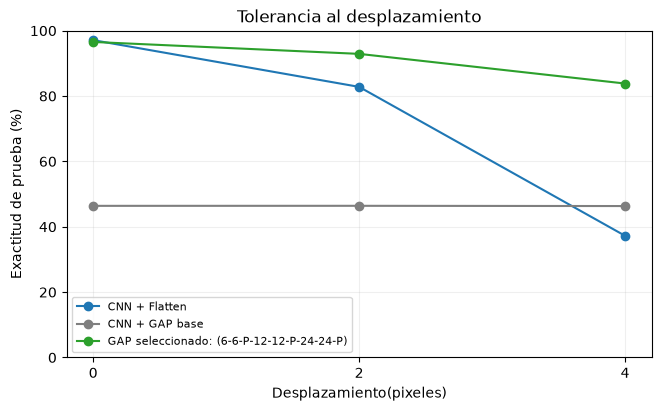

In [26]:
fig, ax = plt.subplots(figsize=(6.5, 4), layout="constrained")
for (nombre, valores), color in zip(exactitudes. items(), ("C0", "C7", "C2")):
    ax.plot(distancias, valores, marker="o", label=nombre, color=color)
ax.set(title="Tolerancia al desplazamiento", xlabel="Desplazamiento(pixeles)",
       ylabel="Exactitud de prueba (%)", xticks=distancias, ylim=(0,100))
ax.legend(fontsize=8)
ax.grid(alpha=0.2)
plt.show()

- Una curva por modelo: azul = Flatten, gris = GAP base, verde = GAP seleccionado.
- La **altura** de la curva indica qué tan bien clasifica; la **pendiente**, cuánto pierde al mover el dígito.

##### 4.5 Interpretación

| Modelo | Parámetros | 0 px | 2 px | 4 px | Caída 0→4 px |
|:--|:--:|:--:|:--:|:--:|:--:|
| CNN + Flatten | 54 330 | 97.10 % | 82.80 % | 37.24 % | 59.86 pp |
| CNN + GAP base | 2 650 | 46.40 % | 46.41 % | 46.34 % | 0.06 pp |
| **GAP seleccionado** | **10 432** | **96.55 %** | **92.90 %** | **83.83 %** | **12.72 pp** |

- **CNN + Flatten:** es la mejor con las imágenes centradas, pero pierde casi 60 puntos a 4 píxeles. Cada peso de su capa densa está ligado a una posición fija del mapa, así que al mover el dígito las activaciones caen en pesos distintos.
- **CNN + GAP base:** su caída es prácticamente cero, pero porque se mantiene en 46 % en todas las distancias. **Una caída pequeña no sirve si la exactitud de partida es baja.**
- **GAP seleccionado:** con las imágenes centradas queda solo 0.55 puntos por debajo de Flatten, y a 4 píxeles conserva **83.83 %**, más del doble que los dos modelos base. No es totalmente invariante: sus tres poolings forman una rejilla de paso 8, y un desplazamiento de 2 o 4 píxeles cambia qué valores agrupa cada ventana.

---

# Pregunta 1:

*¿Cuál fue el cambio más importante para que GAP superara el 95 % en validación?*

**Respuesta:** Intercalar el *max pooling* entre las convoluciones en lugar de dejarlo solo al final. Con las mismas capas y los mismos parámetros, la exactitud subió de 53.33 % a 86.53 % (`16-16-16-P` → `16-P-16-P-16`) y de 54.13 % a 89.67 % (`8-16-32-P` → `8-P-16-P-32`). Esto amplía el campo receptivo, de modo que cada canal ve el dígito completo antes del promedio global. Para pasar del 95 % se completó con dos convoluciones por bloque y un tercer pooling antes de GAP.


# Pregunta 2:

*¿Cuántos parámetros ahorraste frente a Flatten?*

**Respuesta:** El GAP seleccionado (`6-6-P-12-12-P-24-24-P`) tiene **10 432** parámetros entrenables frente a los **54 330** de Flatten, lo que representa un ahorro de **43 898 parámetros (80.8 % menos)**, con 96.40 % de exactitud en validación.


# Pregunta 3:

*¿Tu GAP seleccionado reconoce mejor los dígitos desplazados que Flatten? ¿A partir de qué distancia se aprecia la diferencia?*

**Respuesta:** Sí. A 0 píxeles Flatten es ligeramente mejor (97.10 % contra 96.55 %), pero la diferencia ya se aprecia a **2 píxeles**: el GAP seleccionado obtiene 92.90 % contra 82.80 % de Flatten (10 puntos más). A 4 píxeles la brecha crece a 46.6 puntos (83.83 % contra 37.24 %), y su caída es de 12.72 pp frente a 59.86 pp de Flatten.


---


#### 5. Conclusión

Con este trabajo podemos ver que una cabeza GAP puede igualar a Flatten con muchos menos parámetros, siempre que el extractor convolucional esté diseñado para ella.

Primero, el GAP base fallaba (44 %) no por usar GAP sino porque su extractor era muy local. La decisión que más pesó fue **dónde se ubica el pooling**: intercalarlo entre las convoluciones mejoró más de 30 puntos sin agregar un solo parámetro, porque permite que cada canal vea el dígito completo antes de promediarlo.

Por otro lado, al quitar la capa densa enorme de Flatten se liberó casi todo el presupuesto de parámetros. El modelo seleccionado usa **10 432 parámetros (80.8 % menos que Flatten)** y alcanza 96.40 % en validación y 96.55 % en prueba, prácticamente lo mismo que Flatten.

Por último, la prueba de desplazamiento muestra que hay que mirar tanto la caída como la exactitud que se conserva. El GAP base casi no cae, pero nunca clasificó bien; Flatten clasifica muy bien centrado, pero se desploma al mover el dígito. El GAP seleccionado combina ambas cosas: buena exactitud de partida y **83.83 % a 4 píxeles**, más del doble que cualquiera de los modelos base.


# Referencias

- *LeCun, Y., Bottou, L., Bengio, Y., & Haffner, P. (1998). Gradient-based learning applied to document recognition. Proceedings of the IEEE, 86(11), 2278-2324.*

- *Lin, M., Chen, Q., & Yan, S. (2014). Network In Network. International Conference on Learning Representations (ICLR).*

- *Chollet, F., et al. (2015). Keras. https://keras.io*

- *Raygoza Romero, J. M. (2026). ICD-21: Redes neuronales convolucionales [Notebook de clase]. Introducción a la Ciencia de Datos, CICESE.*


## Extras y Declaración de uso de IA

Se utilizó un modelo de **inteligencia artificial (Anthropic, Claude Opus 5.5)** como asistente para explorar las arquitecturas, organizar la estructura del notebook, revisar el código y dar formato al Markdown.
